# Three car-like ORCA-MPPI routes in warehouse2

This restores the original three-car crossing scenario on the Bench-MR `warehouse2` map. The second route retains the published `testing_warehouse2` start and goal. Each car follows its own RRT-Connect anchor with bicycle-model steering. The pointed end and pale windshield show the **front**; the red bar shows the **rear**. A conservative circular collision envelope contains the drawn car body.

For the denser opposing-traffic stress case, see [`rrt_connect_warehouse2_car_like_traffic_jam.ipynb`](rrt_connect_warehouse2_car_like_traffic_jam.ipynb).

After a native-code update, rebuild with `cmake --build build/release --target mppi_all -j2`, restart the Jupyter kernel, and run all cells. A running kernel keeps an already-imported `mppi_ca_cpp` binary loaded.

![Three car-like warehouse agents](results/rrt_connect_warehouse2_car_like_multiagent/animation.gif)


In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.patches import Circle, Polygon as PolygonPatch
import numpy as np
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if ROOT.name in {'benchmarks', 'example'}:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'benchmarks'))
sys.path.insert(0, str(ROOT / 'example'))

from bench_mr import boundary_obstacles
from rrt_connect import RRTConnectPlanner
import dyn_models
from params_names import *
import utils

suite = json.loads((ROOT / 'benchmarks/bench_mr_tasks.json').read_text())
world = suite['worlds']['warehouse2']


## Editable three-car tasks and geometry

Each start and goal is `[x, y, heading]`. The car body fits inside `ROBOT_RADIUS`, the radius used by RRT-Connect, ORCA, and obstacle checks. The car state includes signed speed and steering angle; MPPI samples jerk and steering rate.


In [2]:
SEED = 42
AGENT_NAMES = [
    'lower-left to upper-right',
    'testing_warehouse2',
    'middle-left to upper-right',
]
CUSTOM_STARTS = np.array([
    [7.5, -70.0,  0.50],
    [7.5, -10.0, -1.58],
    [7.5, -50.0,  0.00],
], dtype=float)
CUSTOM_GOALS = np.array([
    [116.0, -10.0,  0.50],
    [116.0, -70.0, -1.58],
    [116.0, -30.0,  0.00],
], dtype=float)

ROBOT_RADIUS = 0.70
CAR_LENGTH = 1.20
CAR_WIDTH = 0.65
WHEELBASE = 1.00
STEER_LIMIT = 0.60
STEER_RATE_LIMIT = 0.6
MAX_SPEED = 3.0
REVERSE_MAX_SPEED = 0.0  # Main routes are forward-only; the separate maneuver enables reverse.
ACCEL_MAX = 1.5
BRAKE_MAX = 3.0
PLANNER_CLEARANCE = 0.15
JERK_MIN = -1.0
JERK_MAX = 1.0
DT = 0.1

if CUSTOM_STARTS.shape != CUSTOM_GOALS.shape or CUSTOM_STARTS.shape != (len(AGENT_NAMES), 3):
    raise ValueError('Provide one [x, y, heading] start and goal per car')
if not np.isfinite(CUSTOM_STARTS).all() or not np.isfinite(CUSTOM_GOALS).all():
    raise ValueError('Start and goal poses must be finite')
if np.hypot(CAR_LENGTH / 2, CAR_WIDTH / 2) > ROBOT_RADIUS:
    raise ValueError('The car body must fit inside the collision radius')
if WHEELBASE <= 0 or STEER_LIMIT <= 0 or STEER_LIMIT >= np.pi / 2:
    raise ValueError('Wheelbase and steering limit must define a finite turning radius')
reference_task = next(task for task in suite['tasks'] if task['id'] == 'testing_warehouse2')
assert np.allclose(CUSTOM_STARTS[1], reference_task['start'])
assert np.allclose(CUSTOM_GOALS[1], reference_task['goal'])
print(f'{len(AGENT_NAMES)} cars; max speed {MAX_SPEED:.1f}; acceleration {ACCEL_MAX:.1f}; '
      f'braking {BRAKE_MAX:.1f} map units/s²')

# Prediction and experiment duration are independent.
PREDICTION_HORIZON_SECONDS = 6.0
SIM_TIME_FACTOR = 2.0
SIM_TIME_MARGIN_SECONDS = 60.0
GOAL_TOLERANCE = 1.0
OUTPUT_DIR = ROOT / "benchmarks/results/rrt_connect_warehouse2_car_like_multiagent"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


3 cars; max speed 3.0; acceleration 1.5; braking 3.0 map units/s²


## RRT-Connect anchors

Dotted paths are raw RRT-Connect results. Dashed paths are the collision-checked shortcut anchors passed to ORCA-MPPI. The starting cars show their initial headings.


In [3]:
planning_results = []
for agent_id, (start, goal) in enumerate(zip(CUSTOM_STARTS, CUSTOM_GOALS)):
    planner = RRTConnectPlanner(
        obstacles=world['obstacles'], bounds=world['bounds'],
        robot_radius=ROBOT_RADIUS, clearance=PLANNER_CLEARANCE,
        step_size=1.5, max_iterations=100_000, goal_sample_rate=0.05,
        smoothing_iterations=800, seed=SEED + agent_id,
    )
    result = planner.plan(start[:2], goal[:2])
    planning_results.append(result)
    length = sum(np.linalg.norm(np.subtract(b, a))
                 for a, b in zip(result.path, result.path[1:]))
    print(f'{AGENT_NAMES[agent_id]}: {result.iterations} RRT iterations, '
          f'{len(result.path)} anchor vertices, length {length:.1f}')
anchor_paths = [result.path for result in planning_results]


lower-left to upper-right: 266 RRT iterations, 10 anchor vertices, length 145.6
testing_warehouse2: 132 RRT iterations, 11 anchor vertices, length 137.6
middle-left to upper-right: 87 RRT iterations, 6 anchor vertices, length 120.4


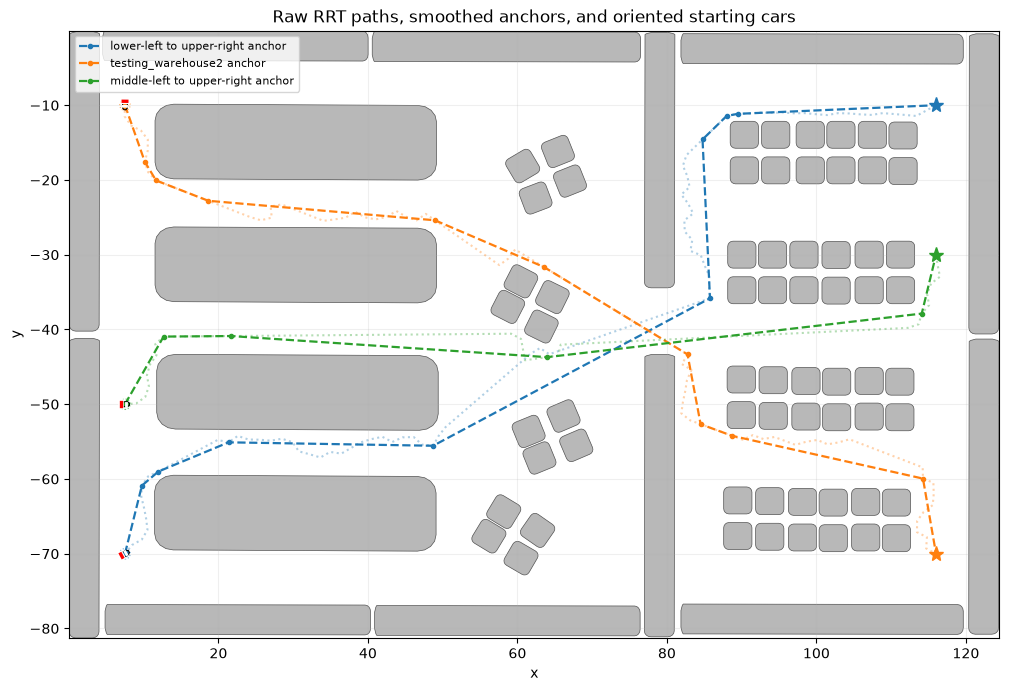

In [4]:
colors = plt.colormaps['tab10'](np.arange(len(AGENT_NAMES)))

def draw_world(ax):
    for vertices in world['obstacles']:
        ax.add_patch(PolygonPatch(vertices, closed=True, facecolor='0.72',
                                  edgecolor='0.32', linewidth=0.5))
    bounds = world['bounds']
    ax.set(xlim=(bounds[0], bounds[2]), ylim=(bounds[1], bounds[3]),
           aspect='equal', xlabel='x', ylabel='y')
    ax.grid(alpha=0.2)

def draw_car(ax, pose, color, alpha=1.0, safety_circle=False):
    """Draw a pointed front, pale windshield, and red rear at the car heading."""
    x, y, heading = pose[:3]
    rotation = np.array([[np.cos(heading), -np.sin(heading)],
                         [np.sin(heading),  np.cos(heading)]])
    def world_points(local):
        return np.asarray(local) @ rotation.T + [x, y]
    half_l, half_w = CAR_LENGTH / 2, CAR_WIDTH / 2
    body = world_points([[-half_l, -half_w], [0.30 * CAR_LENGTH, -half_w],
                         [half_l, -0.45 * half_w], [half_l, 0.45 * half_w],
                         [0.30 * CAR_LENGTH, half_w], [-half_l, half_w]])
    ax.add_patch(PolygonPatch(body, closed=True, facecolor=color,
                              edgecolor='black', linewidth=0.8, alpha=alpha, zorder=5))
    windshield = world_points([[0.12 * CAR_LENGTH, -0.65 * half_w],
                               [0.12 * CAR_LENGTH,  0.65 * half_w]])
    rear = world_points([[-0.88 * half_l, -0.75 * half_w],
                         [-0.88 * half_l,  0.75 * half_w]])
    ax.plot(windshield[:, 0], windshield[:, 1], color='white', linewidth=2.0,
            alpha=alpha, zorder=6)
    ax.plot(rear[:, 0], rear[:, 1], color='white', linewidth=4.0,
            alpha=alpha, zorder=6)
    ax.plot(rear[:, 0], rear[:, 1], color='red', linewidth=2.4,
            alpha=alpha, zorder=7)
    if safety_circle:
        ax.add_patch(Circle((x, y), ROBOT_RADIUS, fill=False, color=color,
                            linestyle=':', linewidth=0.8, alpha=0.65, zorder=4))

fig, ax = plt.subplots(figsize=(12, 8))
draw_world(ax)
for agent_id, (start, goal, result) in enumerate(zip(CUSTOM_STARTS, CUSTOM_GOALS, planning_results)):
    raw, anchor = np.asarray(result.raw_path), np.asarray(result.path)
    color = colors[agent_id]
    ax.plot(raw[:, 0], raw[:, 1], ':', color=color, alpha=0.35)
    ax.plot(anchor[:, 0], anchor[:, 1], '--o', color=color, linewidth=1.6,
            markersize=3, label=f'{AGENT_NAMES[agent_id]} anchor')
    draw_car(ax, start, color, safety_circle=True)
    ax.plot(*goal[:2], '*', color=color, markersize=11)
ax.set_title('Raw RRT paths, smoothed anchors, and oriented starting cars')
ax.legend(fontsize=8)
plt.show()


## Run concurrent car-like ORCA-MPPI inference

The state is `[x, y, heading, velocity, steering angle, acceleration]`; controls are `[jerk, steering rate]`. Native rollouts and Python execution use the same bicycle equations: `a[k+1] = a[k] + j[k] * DT`, `v[k+1] = v[k] + a[k] * DT`, and `steering[k+1] = steering[k] + steering_rate[k] * DT`. Main routes use forward-only speed, jerk bounded by ±1 map units/s³, and steering rate bounded by ±0.6 rad/s. Acceleration, braking, wheelbase, body size, and maximum forward speed retain the original values.

The six-second prediction horizon is separate from the simulation budget, which scales with the longest RRT anchor. Temporally correlated sampling (`0.92`) and bounded tracking/avoidance proposals (`25%` of the batch) reduce control chatter and help cars acquire their anchors. Effort weights are `1000/2000`; successive-command weights are `4000/10000` for jerk/steering rate. Route guidance eases during acquisition or passing stopped/crossing traffic and stays strong behind traffic moving in the same direction.

ORCA remains enabled with this scenario's original warning time and responsibility. Polygon checks and circular collision envelopes remain active. Every car must stop within `GOAL_TOLERANCE` of its goal. `park_at_goal=True` begins bounded braking only when the stopping arc fits inside that goal disk; parked cars remain neighbors. No state is reset, and no command or plotted trace is filtered. Independent diagnostics check every measured bicycle increment, limits, and swept collision gaps.


In [5]:
AGENTS_NUM = len(AGENT_NAMES)
start_states = np.c_[CUSTOM_STARTS, np.zeros((AGENTS_NUM, 3))]
goal_states = np.c_[CUSTOM_GOALS, np.zeros((AGENTS_NUM, 3))]
agent_params = {
    AGENT_SIZE: ROBOT_RADIUS, VISIBILITY_RADIUS: 30.0,
    DIFF_DRIVE_V_MAX: MAX_SPEED, DIFF_DRIVE_V_MIN: -REVERSE_MAX_SPEED,
    LONGITUDINAL_ACCEL_MIN: -BRAKE_MAX, LONGITUDINAL_ACCEL_MAX: ACCEL_MAX,
    LONGITUDINAL_JERK_MIN: JERK_MIN, LONGITUDINAL_JERK_MAX: JERK_MAX,
    DIFF_DRIVE_W_MAX: STEER_LIMIT, DIFF_DRIVE_W_MIN: -STEER_LIMIT,
    STEERING_RATE_MAX: STEER_RATE_LIMIT,
}
agents_params = [agent_params.copy() for _ in range(AGENTS_NUM)]
agent_models = [dyn_models.CarLikeDyn(WHEELBASE) for _ in range(AGENTS_NUM)]
alg_params = {
    SAMPLE_BATCH_SIZE: 256, SAMPLE_TIME_STEPS: int(round(PREDICTION_HORIZON_SECONDS / DT)) + 1, TIME_STEP: DT,
    INIT_VALUE: np.zeros(2), CONTROL_MEAN: np.zeros(2),
    # Stationary variances of temporally coherent [jerk, steering_rate] noise.
    CONTROL_COV: np.diag([0.25, 0.0225]),
    ANCHOR_GUIDED_FRACTION: 0.25, CONTROL_NOISE_CORRELATION: 0.92, ANCHOR_ACQUISITION_SCALE: 0.02,
    JERK_COST_WEIGHT: 1000.0, STEERING_RATE_COST_WEIGHT: 2000.0,
    JERK_CHANGE_COST_WEIGHT: 4000.0, STEERING_RATE_CHANGE_COST_WEIGHT: 10000.0,
    RUNNING_COST_WEIGH: 300.0, TERMINAL_WEIGHT: 2000.0,
    SOFTMAX_TEMPERATURE: 0.25, MA_COST_EN: True,
    MA_DIST_WEIGHT: 1200.0, MA_COLLISION_WEIGHT: 1e7,
    MA_DIST_THREASHOLD: 4.0, USE_CAR_LIKE_DYN: True,
    DIST_BETWEEN_AXLES: WHEELBASE,
    K_ALPHA: -2.96, RAD_EPS: 0.05, VELOCITY_COST_WEIGHT: 0.5,
    TERMINAL_LOOKAHEAD_DISTANCE: 6.0, MA_EN_CLOSE_TO_GOAL_DIST: 1.0,
    MA_EN_CLOSE_TO_GOAL_TS: 3, ORCA_TIME_BOUNDARY: 1.0,
    ORCA_RESPONSIBILITY_FACTOR: 0.5, MA_EXCLUDE_COLLISION_TRAJ: True,
    VELOCITY_COST_CLOSE_TO_GOAL_DIST: 0.7, ANCHOR_PATH_WEIGHT: 3000.0,
    ANCHOR_HEADING_WEIGHT: 1000.0, CONTROL_SMOOTHNESS_WEIGHT: 20.0,
    ANCHOR_FORWARD_WEIGHT: 80000.0, REVERSE_COST_WEIGHT: 1000.0,
}
route_lengths = [sum(np.linalg.norm(np.subtract(b, a)) for a, b in zip(path, path[1:]))
                 for path in anchor_paths]
SIMULATION_SECONDS = int(np.ceil(SIM_TIME_FACTOR * max(route_lengths) / MAX_SPEED + SIM_TIME_MARGIN_SECONDS))
exp_params = {EXP_TIME_STEP: DT, XY_GOAL_TOLERANCE: GOAL_TOLERANCE,
              MAX_EXP_STEPS: int(np.ceil(SIMULATION_SECONDS / DT))}
print(f"Prediction: {PREDICTION_HORIZON_SECONDS:.1f}s; simulation budget: {SIMULATION_SECONDS}s")
expanded_bounds = np.asarray(world['bounds']) + np.array([-1, -1, 1, 1]) * (ROBOT_RADIUS + 0.05)
controller_obstacles = world['obstacles'] + boundary_obstacles(expanded_bounds)
success, collisions, steps, duration, log_state = utils.launch_mppi(
    start_states, goal_states, AGENTS_NUM, agents_params, alg_params, exp_params,
    agent_models, seed=SEED, obstacles=controller_obstacles, anchor_paths=anchor_paths, park_at_goal=True,
)
states = np.asarray(log_state)
xy = states[:, :, :2]
goal_errors = np.linalg.norm(xy[-1] - goal_states[:, :2], axis=1)
# Velocity and steering are physical state, not commanded pose increments.
speeds = states[1:, :, 3]
previous_speeds = states[:-1, :, 3]
accelerations = states[:, :, 5]
speed_rates = np.diff(states[:, :, 3], axis=0) / DT
np.testing.assert_allclose(speed_rates, accelerations[:-1], atol=1e-8)
steering_rates = np.diff(states[:, :, 4], axis=0) / DT
jerks = np.diff(accelerations, axis=0) / DT
# Independently verify bicycle pose propagation as well as acceleration.
expected_xy = speeds[..., None] * np.stack(
    [np.cos(states[:-1, :, 2]), np.sin(states[:-1, :, 2])], axis=-1) * DT
np.testing.assert_allclose(np.diff(xy, axis=0), expected_xy, atol=1e-8)
np.testing.assert_allclose(np.diff(states[:, :, 2], axis=0),
                           speeds / WHEELBASE * np.tan(states[1:, :, 4]) * DT, atol=1e-8)
# Raw differences measure chatter; they are diagnostics, not extra controls.
control_values = np.stack([jerks, steering_rates], axis=-1)
control_rms = np.sqrt(np.mean(control_values**2, axis=(0, 1)))
control_change_rms = np.sqrt(np.mean(np.diff(control_values, axis=0)**2, axis=(0, 1)))
print('RMS [jerk, steering_rate]:', np.round(control_rms, 4))
print('RMS successive-command changes:', np.round(control_change_rms, 4))
print(f'jerk near hard bounds: {np.mean((jerks <= 0.95 * JERK_MIN) | (jerks >= 0.95 * JERK_MAX)):.1%}')
max_acceleration = float(accelerations.max())
max_braking = float(-accelerations.min())
assert np.max(states[:, :, 3]) <= MAX_SPEED + 1e-6
assert np.min(states[:, :, 3]) >= -REVERSE_MAX_SPEED - 1e-6
assert accelerations.max() <= ACCEL_MAX + 1e-6
assert accelerations.min() >= -BRAKE_MAX - 1e-6
assert jerks.min() >= JERK_MIN - 1e-6
assert jerks.max() <= JERK_MAX + 1e-6
assert np.max(np.abs(states[:, :, 4])) <= STEER_LIMIT + 1e-6
assert np.max(np.abs(steering_rates)) <= STEER_RATE_LIMIT + 1e-6

reverse_steps = np.sum(speeds < -0.05, axis=0)
forward_after_reverse = []
for agent_id, name in enumerate(AGENT_NAMES):
    reverse_indices = np.flatnonzero(speeds[:, agent_id] < -0.05)
    if len(reverse_indices) and np.any(speeds[reverse_indices[-1] + 1:, agent_id] > 0.05):
        forward_after_reverse.append(name)
print(f'success={success}, collisions={collisions}, steps={steps}, wall time={duration:.2f}s')
print(f'measured a range=[{-max_braking:.2f}, {max_acceleration:.2f}] units/s²; '
      f'max steering rate={np.max(np.abs(steering_rates)):.2f} rad/s')
print(f'measured jerk range=[{jerks.min():.2f}, {jerks.max():.2f}] units/s³; '
      f'max acceleration step={np.max(np.abs(np.diff(accelerations, axis=0))):.3f}')
print(f'reverse steps by car: {dict(zip(AGENT_NAMES, reverse_steps.tolist()))}')
print(f'reversed then moved forward: {forward_after_reverse}')
for name, error in zip(AGENT_NAMES, goal_errors):
    print(f'{name}: final XY error={error:.2f}')
closest = (np.inf, None, None, None)
for first in range(AGENTS_NUM):
    for second in range(first + 1, AGENTS_NUM):
        distances = np.linalg.norm(xy[:, first] - xy[:, second], axis=1)
        step = int(np.argmin(distances))
        gap = float(distances[step] - 2 * ROBOT_RADIUS)
        if gap < closest[0]:
            closest = (gap, first, second, step)
print(f'closest circular-envelope gap={closest[0]:.3f} '
      f'({AGENT_NAMES[closest[1]]}/{AGENT_NAMES[closest[2]]}, step {closest[3]})')



run_summary = dict(success=bool(success), collisions=int(collisions), steps=int(steps),
                   wall_seconds=float(duration), mppi_seed=SEED,
                   final_goal_errors=dict(zip(AGENT_NAMES, goal_errors.tolist())),
                   unfinished=[name for name, error in zip(AGENT_NAMES, goal_errors)
                               if error > exp_params[XY_GOAL_TOLERANCE]],
                   closest_envelope_gap=float(closest[0]))
(OUTPUT_DIR / 'run_summary.json').write_text(json.dumps(run_summary, indent=2) + '\n')
np.savez_compressed(OUTPUT_DIR / 'trajectories.npz', states=states, dt=DT)

# Tracking diagnostics separate route acquisition/progress from the time budget.
from shapely.geometry import LineString, Point
tracking_metrics = []
for agent_id, path in enumerate(anchor_paths):
    reference = LineString(path)
    distances = np.array([reference.distance(Point(point)) for point in xy[:, agent_id]])
    progress = reference.project(Point(xy[-1, agent_id]))
    metrics = dict(agent=AGENT_NAMES[agent_id], route_length=reference.length,
                   final_progress=progress, progress_fraction=progress / reference.length,
                   rms_route_distance=float(np.sqrt(np.mean(distances**2))),
                   max_route_distance=float(distances.max()))
    tracking_metrics.append(metrics)
    print(f"{metrics['agent']}: route progress {progress:.1f}/{reference.length:.1f}; "
          f"RMS route distance {metrics['rms_route_distance']:.2f}")
run_summary['tracking'] = tracking_metrics
run_summary['orca_enabled'] = bool(alg_params[MA_COST_EN])
# Exclude parked tails so smoothness cannot improve just by waiting longer.
active = (np.abs(previous_speeds) > 0.05) | (np.abs(accelerations[:-1]) > 0.05)
changes = np.diff(control_values, axis=0)
run_summary['smoothness'] = dict(
    active_control_rms=np.sqrt(np.mean(control_values[active]**2, axis=0)).tolist(),
    active_command_change_rms=np.sqrt(np.mean(changes[(active[1:] | active[:-1])]**2, axis=0)).tolist(),
    peak_absolute_jerk=float(np.max(np.abs(jerks))),
    peak_absolute_steering_rate=float(np.max(np.abs(steering_rates))),
    jerk_limits=[JERK_MIN, JERK_MAX], steering_rate_limit=STEER_RATE_LIMIT,
    control_noise_correlation=alg_params[CONTROL_NOISE_CORRELATION],
    anchor_guided_fraction=alg_params[ANCHOR_GUIDED_FRACTION],
    anchor_acquisition_scale=alg_params[ANCHOR_ACQUISITION_SCALE],
)
route_distances = np.stack([
    np.array([LineString(path).distance(Point(point)) for point in xy[1:, agent_id]])
    for agent_id, path in enumerate(anchor_paths)], axis=1)
run_summary['active_rms_route_distance'] = float(np.sqrt(np.mean(route_distances[active]**2)))
print('Active control RMS [jerk, steering rate]:', run_summary['smoothness']['active_control_rms'])
print('Active RMS distance to route:', run_summary['active_rms_route_distance'])

(OUTPUT_DIR / 'run_summary.json').write_text(json.dumps(run_summary, indent=2) + '\n')

# Completion and direction diagnostics from measured states.
run_summary.update(
    prediction_horizon_seconds=PREDICTION_HORIZON_SECONDS,
    simulation_budget_seconds=SIMULATION_SECONDS,
    goal_tolerance=exp_params[XY_GOAL_TOLERANCE],
    final_speeds=states[-1, :, 3].tolist(),
    final_accelerations=states[-1, :, 5].tolist(),
    reverse_distances=(np.maximum(-states[1:, :, 3], 0).sum(axis=0) * DT).tolist(),
)
arrivals = {}
for agent_id, name in enumerate(AGENT_NAMES):
    arrived = ((np.linalg.norm(xy[:, agent_id] - CUSTOM_GOALS[agent_id, :2], axis=1)
                <= exp_params[XY_GOAL_TOLERANCE]) &
               (np.abs(states[:, agent_id, 3]) <= 1e-8) &
               (np.abs(states[:, agent_id, 5]) <= 1e-8))
    indices = np.flatnonzero(arrived)
    arrivals[name] = float(indices[0] * DT) if len(indices) else None
run_summary['arrival_seconds'] = arrivals

# Independent continuous footprint checks on all measured motion segments.
from shapely.geometry import Polygon as ObstaclePolygon, box
static_geometry = [ObstaclePolygon(vertices) for vertices in world['obstacles']]
static_geometry.append(box(*world['bounds']).boundary)
run_summary['min_swept_static_gap'] = min(
    LineString(xy[:, agent_id]).distance(obstacle) - ROBOT_RADIUS
    for agent_id in range(AGENTS_NUM) for obstacle in static_geometry)
swept_pair_gap = float('inf')
for first in range(AGENTS_NUM):
    for second in range(first + 1, AGENTS_NUM):
        relative = xy[:, first] - xy[:, second]
        delta = np.diff(relative, axis=0)
        squared = np.sum(delta**2, axis=1)
        fraction = np.divide(-np.sum(relative[:-1] * delta, axis=1), squared,
                             out=np.zeros_like(squared), where=squared > 0)
        fraction = np.clip(fraction, 0, 1)
        swept = np.linalg.norm(relative[:-1] + fraction[:, None] * delta, axis=1)
        swept_pair_gap = min(swept_pair_gap, float(swept.min()) - 2 * ROBOT_RADIUS)
run_summary['min_swept_pair_gap'] = swept_pair_gap
(OUTPUT_DIR / 'run_summary.json').write_text(json.dumps(run_summary, indent=2) + '\n')
print('Arrival times (s):', arrivals)
print('Reverse travel (map units):', dict(zip(AGENT_NAMES, np.round(run_summary['reverse_distances'], 3))))


Prediction: 6.0s; simulation budget: 158s
RMS [jerk, steering_rate]: [0.3951 0.1369]
RMS successive-command changes: [0.2173 0.0704]
jerk near hard bounds: 8.9%
success=True, collisions=0.0, steps=619, wall time=22.52s
measured a range=[-1.56, 1.00] units/s²; max steering rate=0.60 rad/s
measured jerk range=[-1.00, 1.00] units/s³; max acceleration step=0.100
reverse steps by car: {'lower-left to upper-right': 0, 'testing_warehouse2': 0, 'middle-left to upper-right': 0}
reversed then moved forward: []
lower-left to upper-right: final XY error=0.67
testing_warehouse2: final XY error=0.80
middle-left to upper-right: final XY error=0.46
closest circular-envelope gap=1.205 (testing_warehouse2/middle-left to upper-right, step 310)
lower-left to upper-right: route progress 145.0/145.6; RMS route distance 0.20
testing_warehouse2: route progress 136.8/137.6; RMS route distance 0.15
middle-left to upper-right: route progress 119.9/120.4; RMS route distance 0.22
Active control RMS [jerk, steering

## Executed paths, car orientation, and speed

Solid lines show actual trajectories. The final body poses retain simulated headings; the close-ups mark the white front and red rear. The raw state and control plots show velocity, signed acceleration, jerk, and steering angle; dashed lines are physical limits. The animation follows the first car while the full map stays visible.


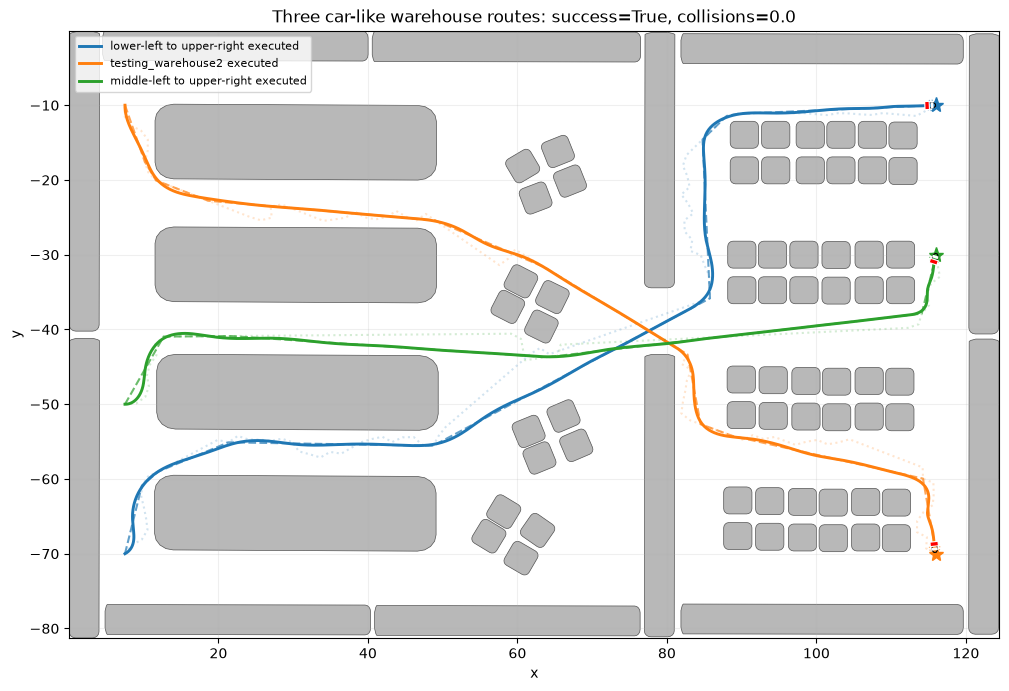

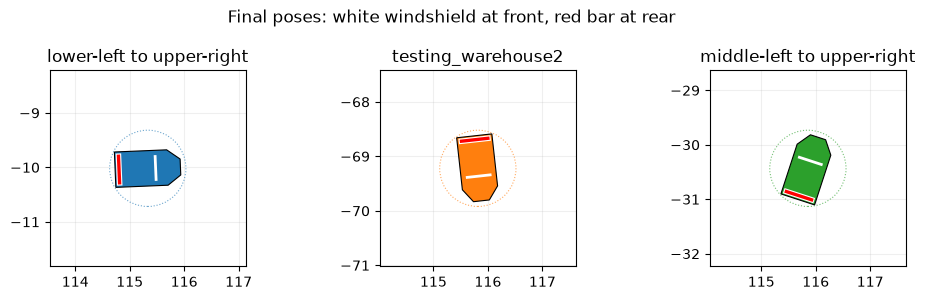

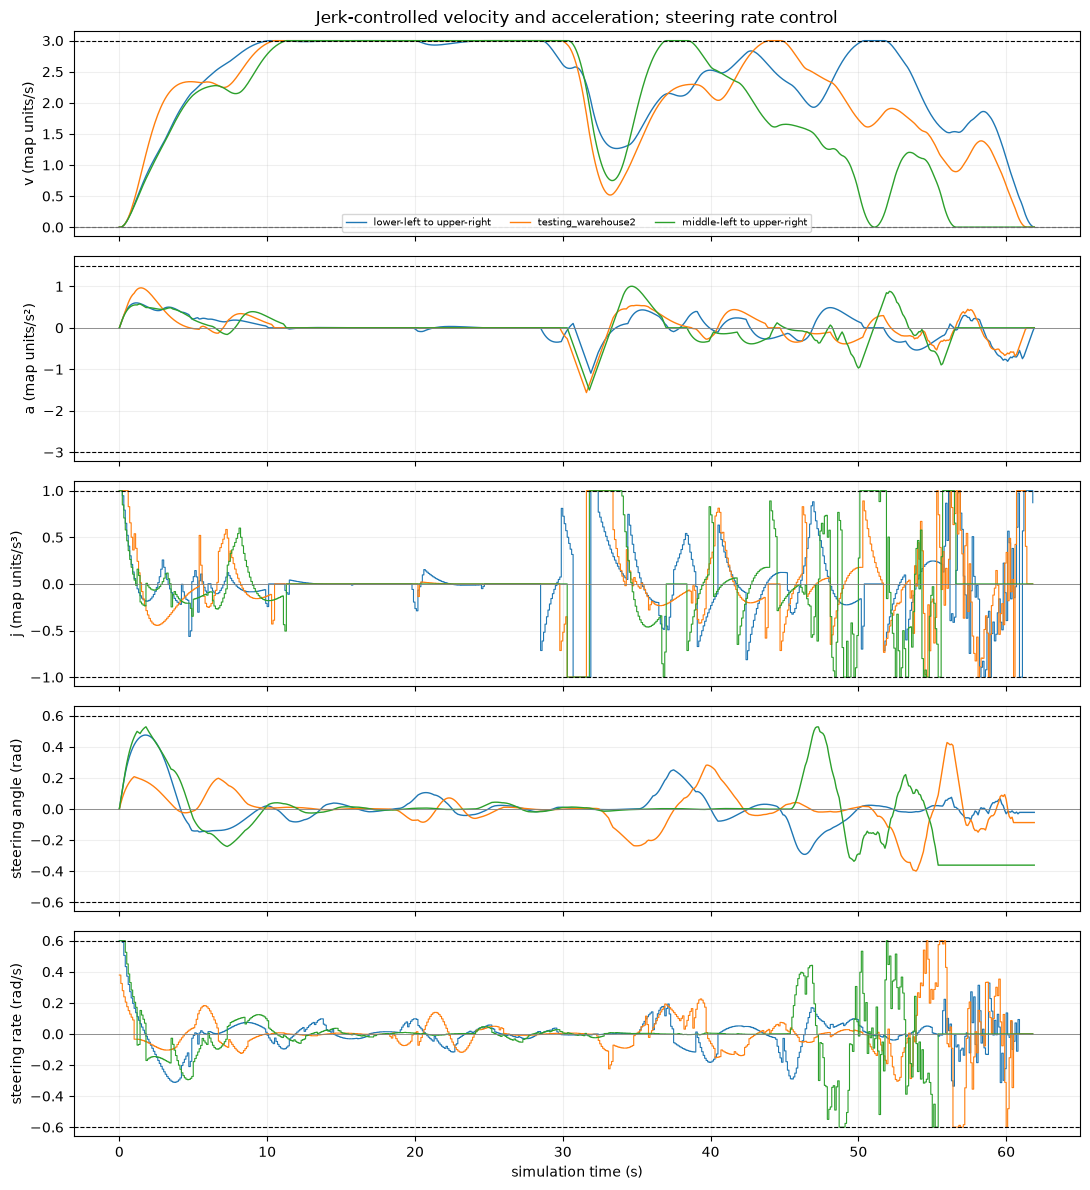

In [6]:
fig, ax = plt.subplots(figsize=(12, 8))
draw_world(ax)
for agent_id, (goal, result) in enumerate(zip(CUSTOM_GOALS, planning_results)):
    color = colors[agent_id]
    raw, anchor = np.asarray(result.raw_path), np.asarray(result.path)
    ax.plot(raw[:, 0], raw[:, 1], ':', color=color, alpha=0.2)
    ax.plot(anchor[:, 0], anchor[:, 1], '--', color=color, alpha=0.7)
    ax.plot(xy[:, agent_id, 0], xy[:, agent_id, 1], color=color,
            linewidth=2.1, label=f'{AGENT_NAMES[agent_id]} executed')
    draw_car(ax, states[-1, agent_id], color, safety_circle=True)
    ax.plot(*goal[:2], '*', color=color, markersize=11)
ax.set_title(f'Three car-like warehouse routes: success={success}, collisions={collisions}')
ax.legend(fontsize=8)
plt.show()

fig, close_axes = plt.subplots(1, AGENTS_NUM, figsize=(10, 3))
for agent_id, ax_close in enumerate(close_axes):
    final_pose = states[-1, agent_id]
    draw_car(ax_close, final_pose, colors[agent_id], safety_circle=True)
    ax_close.set(xlim=(final_pose[0] - 1.8, final_pose[0] + 1.8),
                 ylim=(final_pose[1] - 1.8, final_pose[1] + 1.8),
                 aspect='equal', title=AGENT_NAMES[agent_id])
    ax_close.grid(alpha=0.2)
fig.suptitle('Final poses: white windshield at front, red bar at rear')
fig.tight_layout()
plt.show()

# Raw state/control differences: no smoothing or moving averages.
fig, axes = plt.subplots(5, 1, figsize=(11, 12), sharex=True)
state_times = np.arange(len(states)) * DT
control_times = state_times[:-1]
for agent_id, agent_name in enumerate(AGENT_NAMES):
    color = colors[agent_id]
    axes[0].plot(state_times, states[:, agent_id, 3], color=color, label=agent_name, linewidth=1)
    axes[1].plot(state_times, accelerations[:, agent_id], color=color, linewidth=1)
    axes[2].step(control_times, jerks[:, agent_id], where='post', color=color, linewidth=0.8)
    axes[3].plot(state_times, states[:, agent_id, 4], color=color, linewidth=1)
    axes[4].step(control_times, steering_rates[:, agent_id], where='post', color=color, linewidth=0.8)
axes[0].axhline(MAX_SPEED, color='black', linestyle='--', linewidth=0.8)
axes[0].axhline(-REVERSE_MAX_SPEED, color='black', linestyle='--', linewidth=0.8)
axes[0].set(ylabel='v (map units/s)', title='Jerk-controlled velocity and acceleration; steering rate control')
axes[0].legend(fontsize=7, ncol=3)
axes[1].axhline(ACCEL_MAX, color='black', linestyle='--', linewidth=0.8)
axes[1].axhline(-BRAKE_MAX, color='black', linestyle='--', linewidth=0.8)
axes[1].set(ylabel='a (map units/s²)')
axes[2].axhline(JERK_MAX, color='black', linestyle='--', linewidth=0.8)
axes[2].axhline(JERK_MIN, color='black', linestyle='--', linewidth=0.8)
axes[2].set(ylabel='j (map units/s³)')
axes[3].axhline(STEER_LIMIT, color='black', linestyle='--', linewidth=0.8)
axes[3].axhline(-STEER_LIMIT, color='black', linestyle='--', linewidth=0.8)
axes[3].set(ylabel='steering angle (rad)')
axes[4].axhline(STEER_RATE_LIMIT, color='black', linestyle='--', linewidth=0.8)
axes[4].axhline(-STEER_RATE_LIMIT, color='black', linestyle='--', linewidth=0.8)
axes[4].set(ylabel='steering rate (rad/s)', xlabel='simulation time (s)')
for ax in axes:
    ax.axhline(0, color='gray', linewidth=0.6)
    ax.grid(alpha=0.2)
fig.tight_layout()
DYNAMICS_PLOT_PATH = OUTPUT_DIR / 'dynamics.png'
fig.savefig(DYNAMICS_PLOT_PATH, dpi=160)
plt.show()


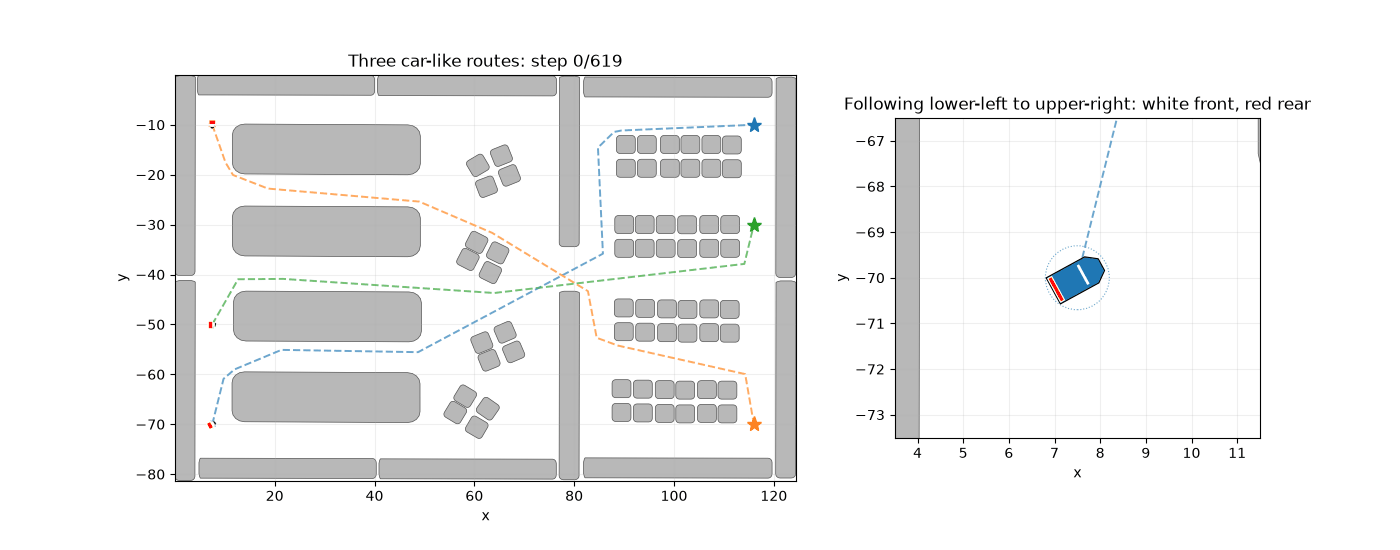

In [7]:
fig, (ax_map, ax_close) = plt.subplots(
    1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1.7, 1]}
)
frame_indices = np.unique(np.linspace(0, len(states) - 1, min(120, len(states))).astype(int))
FOLLOW_AGENT = 0

def animate(frame_number):
    state_index = int(frame_indices[frame_number])
    ax_map.clear()
    ax_close.clear()
    draw_world(ax_map)
    draw_world(ax_close)
    follow_pose = states[state_index, FOLLOW_AGENT]
    ax_close.set(xlim=(follow_pose[0] - 4, follow_pose[0] + 4),
                 ylim=(follow_pose[1] - 3.5, follow_pose[1] + 3.5))
    for agent_id, (goal, anchor_path) in enumerate(zip(CUSTOM_GOALS, anchor_paths)):
        color = colors[agent_id]
        anchor = np.asarray(anchor_path)
        for ax in (ax_map, ax_close):
            ax.plot(anchor[:, 0], anchor[:, 1], '--', color=color,
                    alpha=0.65, linewidth=1.4)
            ax.plot(xy[:state_index + 1, agent_id, 0],
                    xy[:state_index + 1, agent_id, 1],
                    color=color, linewidth=2)
            draw_car(ax, states[state_index, agent_id], color, safety_circle=True)
            ax.plot(*goal[:2], '*', color=color, markersize=11)
    ax_map.set_title(f'Three car-like routes: step {state_index}/{len(states) - 1}')
    ax_close.set_title(f'Following {AGENT_NAMES[FOLLOW_AGENT]}: white front, red rear')

animation = FuncAnimation(fig, animate, frames=len(frame_indices), interval=100)
GIF_PATH = OUTPUT_DIR / 'animation.gif'
animation.save(GIF_PATH, writer=PillowWriter(fps=10))
plt.close(fig)
display(Image(filename=str(GIF_PATH)))


## Reverse, stop, and drive forward

This separate maneuver demonstrates the signed bicycle-model speed on the same warehouse map. The car backs from x=75 to x=71 at at most 0.6 units/s, passes smoothly through zero speed before changing direction, then follows a new RRT-Connect anchor toward x=90 at up to 2.0 units/s. The full measured velocity, acceleration, and steering state carry over through the waypoint change. The route switch is a task instruction; reverse motion and the gear transition are handled by the controller.


In [8]:
import mppi_ca_cpp as mppi

reverse_start = np.array([75.0, -41.5, 0.0, 0.0, 0.0, 0.0])
reverse_goal = np.array([71.0, -41.5, 0.0])
forward_goal = np.array([90.0, -41.5, 0.0])
reverse_planner = RRTConnectPlanner(
    obstacles=world['obstacles'], bounds=world['bounds'],
    robot_radius=ROBOT_RADIUS, clearance=PLANNER_CLEARANCE,
    step_size=1.5, smoothing_iterations=800, seed=42,
)
assert all(reverse_planner.point_is_free(point[:2])
           for point in (reverse_start, reverse_goal, forward_goal))
assert reverse_planner.segment_is_free(reverse_start[:2], reverse_goal[:2])
reverse_anchor = [reverse_start[:2].tolist(), reverse_goal[:2].tolist()]
forward_anchor = reverse_planner.plan(reverse_goal[:2], forward_goal[:2]).path

reverse_agent_params = agent_params | {
    DIFF_DRIVE_V_MAX: 2.0, DIFF_DRIVE_V_MIN: -0.6, LONGITUDINAL_JERK_MIN: -2.0, LONGITUDINAL_JERK_MAX: 2.0,
    STEERING_RATE_MAX: 2.0, LONGITUDINAL_ACCEL_MIN: -4.0, LONGITUDINAL_ACCEL_MAX: 1.0,
}
reverse_alg_params = alg_params | {
    MA_COST_EN: False,  # A separate one-car reverse/forward task.
    SAMPLE_BATCH_SIZE: 160, SAMPLE_TIME_STEPS: 15,
    CONTROL_COV: np.diag([0.25, 0.04]), CONTROL_NOISE_CORRELATION: 0.0,
    ANCHOR_GUIDED_FRACTION: 0.0, ANCHOR_ACQUISITION_SCALE: 1.0,
    ANCHOR_PATH_WEIGHT: 2000.0, ANCHOR_HEADING_WEIGHT: 500.0,
    ANCHOR_FORWARD_WEIGHT: 0.0, REVERSE_COST_WEIGHT: 0.0,
    JERK_COST_WEIGHT: 100.0, STEERING_RATE_COST_WEIGHT: 300.0,
    JERK_CHANGE_COST_WEIGHT: 500.0, STEERING_RATE_CHANGE_COST_WEIGHT: 1000.0,
    TERMINAL_LOOKAHEAD_DISTANCE: 2.0,
}
reverse_controller = mppi.Controller()
reverse_controller.set_agent_params(mppi.convert_agent_params(reverse_agent_params))
reverse_controller.set_alg_params(mppi.convert_alg_params(reverse_alg_params))
reverse_controller.set_obstacles(controller_obstacles)
reverse_controller.set_anchor_path(reverse_anchor)
mppi.set_random_seed(23)
reverse_model = dyn_models.CarLikeDyn(WHEELBASE)
reverse_model.configure_limits(reverse_agent_params)
reverse_states = [reverse_start.copy()]
reverse_controls = []
reverse_phase = 'reverse'
switch_step = None
for step in range(300):
    current = reverse_states[-1]
    target = reverse_goal if reverse_phase == 'reverse' else forward_goal
    control, _ = reverse_controller.next_step(
        current, np.empty((0, 4)), np.empty(0), target)
    following = current.copy()
    following = (reverse_model.state_shift(current, DT)
                 + reverse_model.dynamic_model(current, control, DT))
    reverse_states.append(following)
    reverse_controls.append(control.copy())
    if reverse_phase == 'reverse' and np.linalg.norm(following[:2] - reverse_goal[:2]) < 0.6:
        reverse_phase = 'forward'
        switch_step = step + 1
        reverse_controller.set_anchor_path(forward_anchor)
    if reverse_phase == 'forward' and np.linalg.norm(following[:2] - forward_goal[:2]) < 1.0:
        break
reverse_states = np.asarray(reverse_states)
reverse_controls = np.asarray(reverse_controls)
reverse_speeds = reverse_states[1:, 3]
reverse_accelerations = reverse_states[:, 5]
reverse_jerks = reverse_controls[:, 0]
np.testing.assert_allclose(np.diff(reverse_accelerations) / DT, reverse_jerks, atol=1e-8)
assert reverse_jerks.min() >= reverse_agent_params[LONGITUDINAL_JERK_MIN] - 1e-8
assert reverse_jerks.max() <= reverse_agent_params[LONGITUDINAL_JERK_MAX] + 1e-8
np.testing.assert_allclose(np.diff(reverse_states[:, 3]) / DT, reverse_accelerations[:-1], atol=1e-8)
assert reverse_accelerations.min() >= -4.0 - 1e-8
assert reverse_accelerations.max() <= 1.0 + 1e-8
assert np.max(np.abs(np.diff(reverse_states[:, 4]) / DT)) <= reverse_agent_params[STEERING_RATE_MAX] + 1e-8
assert switch_step is not None
assert np.any(reverse_speeds[:switch_step] < -0.05)
assert np.any(reverse_speeds[switch_step:] > 0.05)
assert np.max(-reverse_speeds) <= -reverse_agent_params[DIFF_DRIVE_V_MIN] + 1e-6
assert np.max(reverse_speeds) <= 2.0 + 1e-6
assert np.linalg.norm(reverse_states[-1, :2] - forward_goal[:2]) < 1.0
print(f'Reversed for {np.sum(reverse_speeds < -0.05)} steps, changed task at step {switch_step}, '
      f'then drove forward for {np.sum(reverse_speeds[switch_step:] > 0.05)} steps.')
print(f'Peak reverse={max(0.0, -reverse_speeds.min()):.2f}, '
      f'peak forward={reverse_speeds.max():.2f} units/s; '
      f'final goal error={np.linalg.norm(reverse_states[-1, :2] - forward_goal[:2]):.2f}.')


Reversed for 74 steps, changed task at step 71, then drove forward for 125 steps.
Peak reverse=0.60, peak forward=1.76 units/s; final goal error=0.97.


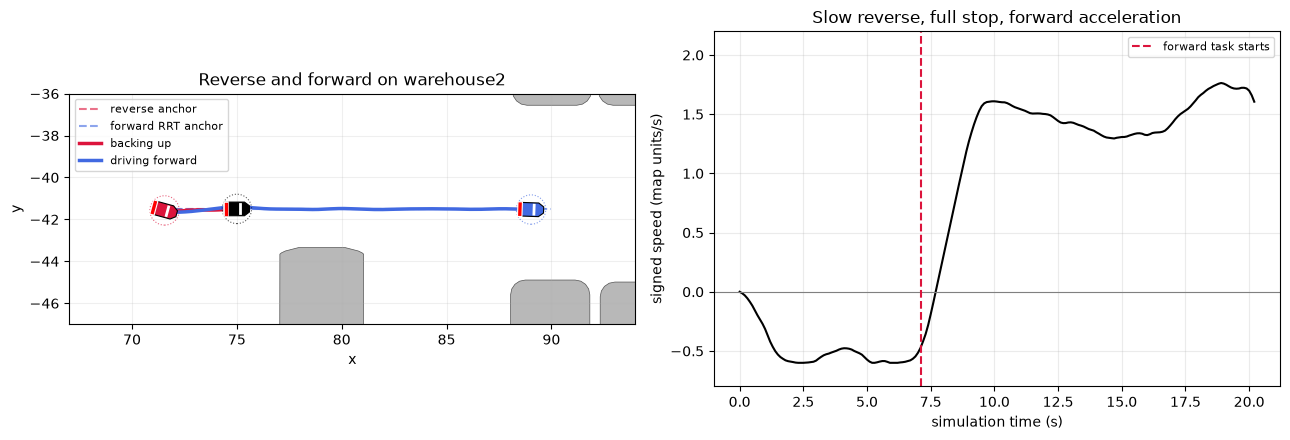

In [9]:
fig, (ax_route, ax_speed) = plt.subplots(1, 2, figsize=(13, 4.5))
draw_world(ax_route)
ax_route.set(xlim=(67, 94), ylim=(-47, -36), title='Reverse and forward on warehouse2')
ax_route.plot(*np.asarray(reverse_anchor).T, '--', color='crimson', alpha=0.6, label='reverse anchor')
ax_route.plot(*np.asarray(forward_anchor).T, '--', color='royalblue', alpha=0.6, label='forward RRT anchor')
ax_route.plot(reverse_states[:switch_step + 1, 0], reverse_states[:switch_step + 1, 1],
              color='crimson', linewidth=2.5, label='backing up')
ax_route.plot(reverse_states[switch_step:, 0], reverse_states[switch_step:, 1],
              color='royalblue', linewidth=2.5, label='driving forward')
for pose, color in ((reverse_states[0], 'black'),
                    (reverse_states[switch_step], 'crimson'),
                    (reverse_states[-1], 'royalblue')):
    draw_car(ax_route, pose, color, safety_circle=True)
ax_route.legend(fontsize=8)
ax_speed.plot(np.arange(len(reverse_speeds)) * DT, reverse_speeds, color='black')
ax_speed.axhline(0, color='gray', linewidth=0.8)
ax_speed.axvline(switch_step * DT, color='crimson', linestyle='--', label='forward task starts')
ax_speed.set(xlabel='simulation time (s)', ylabel='signed speed (map units/s)',
             title='Slow reverse, full stop, forward acceleration', ylim=(-0.8, 2.2))
ax_speed.grid(alpha=0.25)
ax_speed.legend(fontsize=8)
fig.tight_layout()
plt.show()


The main scenario uses forward-only motion and the gentler profile above. The following historical comparison retains its original signed-speed limits and sampling settings explicitly, so changing the main scenario does not silently change the comparison.


## Historical seeded comparison of raw controls

A two-bend anchor in free space isolates the control costs and sampling changes. Both runs use the same native dynamics, physical limits, 26-second duration, and seed. The previous magnitude-only configuration uses variances `[0.5625, 0.04]`, jerk/steering-rate weights `100/300`, and zero command-change weights. The temporal configuration keeps the magnitude costs, adds command-change weights `500/1000`, and uses variances `[0.25, 0.04]`. Steering noise stays at 0.2 rad/s (10% of its hard bound), preserving exploration of tight starting turns; jerk noise falls from 0.75 to 0.5. RMS successive-command differences measure high-frequency chatter, and goal error checks progress. No trace is filtered.


Previous {"rms_control": [0.9338238586172687, 0.40902752979755846], "rms_command_change": [0.9708213354644196, 0.5815124323222931], "jerk_saturation_fraction": 0.10384615384615385, "goal_error": 0.005287201137123432, "jerk_cost_weight": 100.0, "steering_rate_cost_weight": 300.0, "jerk_change_cost_weight": 0.0, "steering_rate_change_cost_weight": 0.0, "sampling_variances": [0.5625, 0.04]}
Temporal {"rms_control": [0.8302576905117339, 0.3126290125020173], "rms_command_change": [0.523211742881539, 0.33926902434142614], "jerk_saturation_fraction": 0.06923076923076923, "goal_error": 0.05553831907470621, "jerk_cost_weight": 100.0, "steering_rate_cost_weight": 300.0, "jerk_change_cost_weight": 500.0, "steering_rate_change_cost_weight": 1000.0, "sampling_variances": [0.25, 0.04]}
Reduction in RMS command changes [jerk, steering_rate]: [46.1 41.7] %


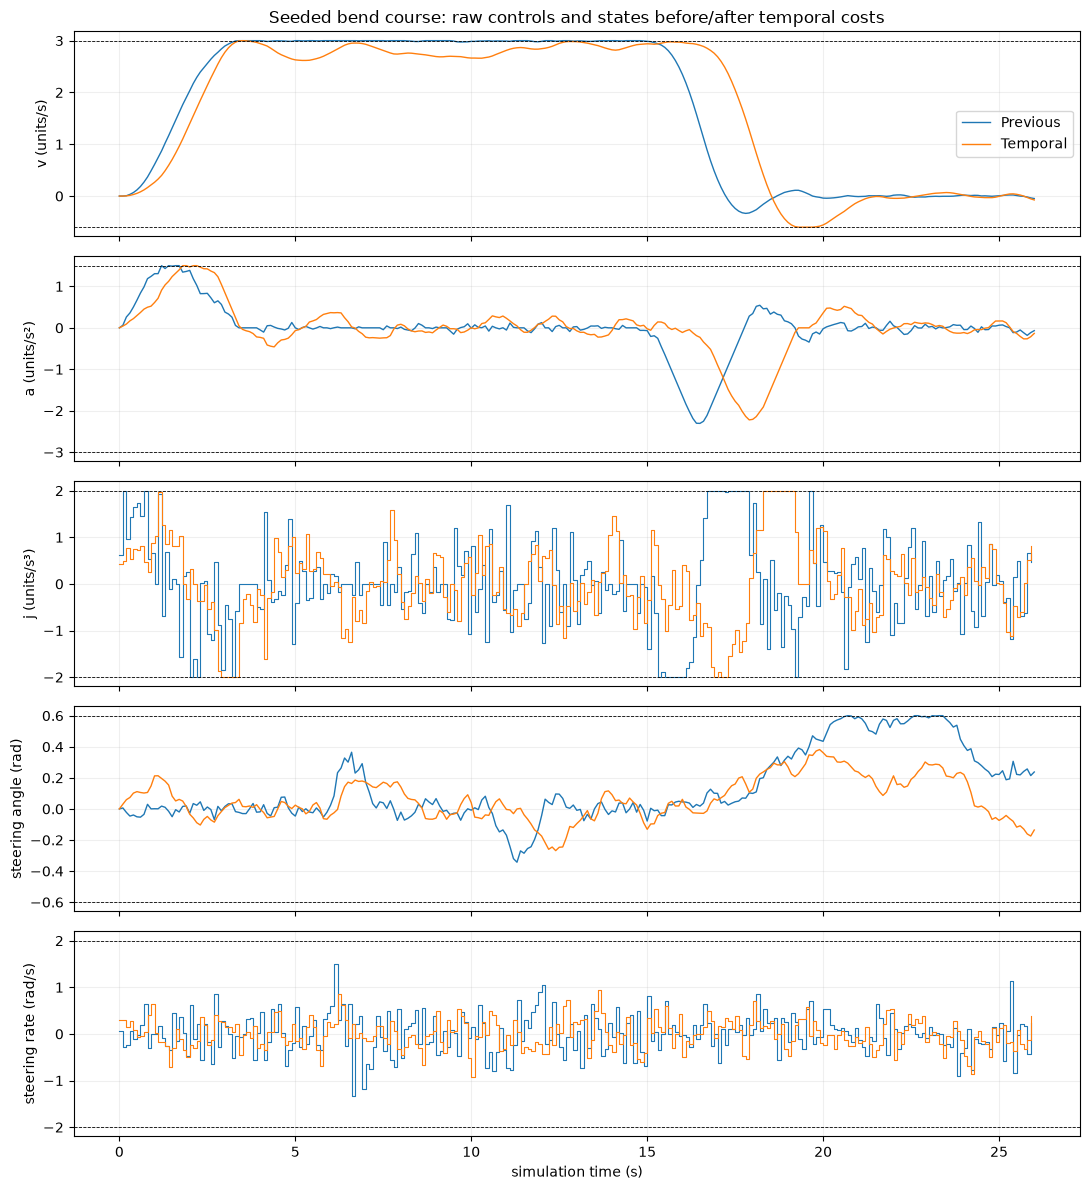

In [10]:
# Same native dynamics, anchor, physical limits and seed in both runs.
# Free space isolates the effect of regularization from obstacle/ORCA decisions.
comparison_anchor = [(0.0, 0.0), (15.0, 0.0), (25.0, 10.0), (40.0, 10.0)]
comparison_goal = np.array([40.0, 10.0, 0.0])
comparison_runs = {}
comparison_agent_params = agent_params | {
    DIFF_DRIVE_V_MIN: -0.6, LONGITUDINAL_JERK_MIN: -2.0, LONGITUDINAL_JERK_MAX: 2.0,
    STEERING_RATE_MAX: 2.0,
}
comparison_alg_params = reverse_alg_params | {
    TERMINAL_LOOKAHEAD_DISTANCE: 6.0,
}
for label, settings in {
    'Previous': {JERK_COST_WEIGHT: 100.0, STEERING_RATE_COST_WEIGHT: 300.0,
                 JERK_CHANGE_COST_WEIGHT: 0.0, STEERING_RATE_CHANGE_COST_WEIGHT: 0.0,
                 CONTROL_COV: np.diag([0.5625, 0.04])},
    'Temporal': {},
}.items():
    params = comparison_alg_params | {MA_COST_EN: False} | settings
    controller = mppi.Controller()
    controller.set_agent_params(mppi.convert_agent_params(comparison_agent_params))
    controller.set_alg_params(mppi.convert_alg_params(params))
    controller.set_anchor_path(comparison_anchor)
    mppi.set_random_seed(23)
    model = dyn_models.CarLikeDyn(WHEELBASE)
    model.configure_limits(comparison_agent_params)
    trace = [np.zeros(6)]
    commands = []
    for _ in range(260):
        command, rollouts = controller.next_step(
            trace[-1], np.empty((0, 4)), np.empty(0), comparison_goal)
        following = model.state_shift(trace[-1], DT) + model.dynamic_model(trace[-1], command, DT)
        np.testing.assert_allclose((following[[5, 4]] - trace[-1][[5, 4]]) / DT,
                                   command, atol=1e-8)
        trace.append(following)
        commands.append(command.copy())
    trace, commands = np.asarray(trace), np.asarray(commands)
    np.testing.assert_allclose(np.diff(trace[:, 3]) / DT, trace[:-1, 5], atol=1e-8)
    assert trace[:, 3].min() >= comparison_agent_params[DIFF_DRIVE_V_MIN] - 1e-8
    assert trace[:, 3].max() <= MAX_SPEED + 1e-8
    assert trace[:, 5].min() >= -BRAKE_MAX - 1e-8
    assert trace[:, 5].max() <= ACCEL_MAX + 1e-8
    assert commands[:, 0].min() >= comparison_agent_params[LONGITUDINAL_JERK_MIN] - 1e-8
    assert commands[:, 0].max() <= comparison_agent_params[LONGITUDINAL_JERK_MAX] + 1e-8
    assert abs(commands[:, 1]).max() <= comparison_agent_params[STEERING_RATE_MAX] + 1e-8
    assert abs(trace[:, 4]).max() <= STEER_LIMIT + 1e-8
    metrics = {
        'rms_control': np.sqrt(np.mean(commands**2, axis=0)).tolist(),
        'rms_command_change': np.sqrt(np.mean(np.diff(commands, axis=0)**2, axis=0)).tolist(),
        'jerk_saturation_fraction': float(np.mean(abs(commands[:, 0]) >= 0.95 * comparison_agent_params[LONGITUDINAL_JERK_MAX])),
        'goal_error': float(np.linalg.norm(trace[-1, :2] - comparison_goal[:2])),
        'jerk_cost_weight': params[JERK_COST_WEIGHT],
        'steering_rate_cost_weight': params[STEERING_RATE_COST_WEIGHT],
        'jerk_change_cost_weight': params[JERK_CHANGE_COST_WEIGHT],
        'steering_rate_change_cost_weight': params[STEERING_RATE_CHANGE_COST_WEIGHT],
        'sampling_variances': np.diag(params[CONTROL_COV]).tolist(),
    }
    assert metrics['goal_error'] < 3.0
    comparison_runs[label] = {'states': trace, 'controls': commands, 'metrics': metrics}
    print(label, json.dumps(metrics))
original = np.asarray(comparison_runs['Previous']['metrics']['rms_command_change'])
regularized = np.asarray(comparison_runs['Temporal']['metrics']['rms_command_change'])
print('Reduction in RMS command changes [jerk, steering_rate]:',
      np.round(100 * (1 - regularized / original), 1), '%')

fig, axes = plt.subplots(5, 1, figsize=(11, 12), sharex=True)
for label, result in comparison_runs.items():
    trace, commands = result['states'], result['controls']
    t = np.arange(len(trace)) * DT
    axes[0].plot(t, trace[:, 3], label=label, linewidth=1)
    axes[1].plot(t, trace[:, 5], linewidth=1)
    axes[2].step(t[:-1], commands[:, 0], where='post', linewidth=0.8)
    axes[3].plot(t, trace[:, 4], linewidth=1)
    axes[4].step(t[:-1], commands[:, 1], where='post', linewidth=0.8)
for ax, label, bounds in zip(axes, ['v (units/s)', 'a (units/s²)', 'j (units/s³)',
                                  'steering angle (rad)', 'steering rate (rad/s)'],
                            [(comparison_agent_params[DIFF_DRIVE_V_MIN], MAX_SPEED), (-BRAKE_MAX, ACCEL_MAX),
                             (comparison_agent_params[LONGITUDINAL_JERK_MIN], comparison_agent_params[LONGITUDINAL_JERK_MAX]), (-STEER_LIMIT, STEER_LIMIT),
                             (-comparison_agent_params[STEERING_RATE_MAX], comparison_agent_params[STEERING_RATE_MAX])]):
    ax.set_ylabel(label)
    for bound in bounds:
        ax.axhline(bound, color='black', linestyle='--', linewidth=0.6)
    ax.grid(alpha=0.2)
axes[0].set_title('Seeded bend course: raw controls and states before/after temporal costs')
axes[0].legend()
axes[-1].set_xlabel('simulation time (s)')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'car_control_regularization_comparison.png', dpi=160)
(OUTPUT_DIR / 'car_control_regularization_metrics.json').write_text(
    json.dumps({label: run['metrics'] for label, run in comparison_runs.items()}, indent=2) + '\n')
plt.show()


## Verify completion, physics, and collision clearance


In [11]:
# A completed run means every car is physically at rest at its finish.
assert success, 'The selected tasks did not all finish within the simulation budget'
assert collisions == 0, 'The measured run contains collisions'
assert not run_summary['unfinished']
assert run_summary['orca_enabled']
assert np.max(goal_errors) <= exp_params[XY_GOAL_TOLERANCE]
np.testing.assert_allclose(states[-1, :, 3], 0, atol=1e-8)
np.testing.assert_allclose(states[-1, :, 5], 0, atol=1e-8)
assert run_summary['min_swept_static_gap'] >= -1e-7
assert run_summary['min_swept_pair_gap'] >= -1e-7
print(f'Verified {AGENTS_NUM}/{AGENTS_NUM} cars stopped at their finishes, '
      f'zero collisions, ORCA enabled; {steps * DT:.1f} simulated seconds.')
assert np.min(states[:, :, 3]) >= -1e-8, 'Main routes must stay forward-only'


Verified 3/3 cars stopped at their finishes, zero collisions, ORCA enabled; 61.9 simulated seconds.
